<h1>Раздел 1<h1>
<h2>Основы работы с моделями нейронных сетей<h2/>

Этот блок подключает внешнее облачное хранилище Google Drive к виртуальной файловой системе среды Colab путём монтирования по указанному пути /content/drive. Это необходимо для долговременного хранения и доступа к данным, поскольку сама среда Colab является эфемерной — её локальное хранилище очищается после завершения сессии.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Шаг 1**
Импорт библиотек, необходимых для работы.

In [4]:
!pip install torchvision

In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader, Dataset

from torchvision import datasets
from torchvision.transforms import ToTensor, Resize

import numpy as np

import matplotlib.pyplot as plt
import matplotlib.image as mpimg

**Шаг 2**
Загрузка открытых датасетов из пакета datasets фреймворка pytorch

Загружаем датасет FashionMNIST из torchvision — 70 000 изображений одежды 28×28, 10 классов. train=True — обучающая выборка (60 000), train=False — тестовая (10 000). root="data" — папка для хранения. download=True — качает автоматически, если файлов нет. transform=ToTensor() — превращает картинку в тензор PyTorch и нормализует пиксели из [0,255] в [0,1]. Результат — две переменные: training_data и test_data.

In [6]:
# Загрузка обучающего датасета.
training_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor(),
)

# Загрузка тестового датасета.
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
)

100%|██████████| 26.4M/26.4M [00:00<00:00, 114MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 3.62MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 60.9MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 13.4MB/s]


In [7]:
# Загрузка классов данных, присутствующих в датасете
test_data.classes
#test_data.data

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

**Шаг 3**
После того, как датасеты были загружены, данные из них необходимо упаковать в пакеты (батчи). Основное преимущество нейросетей заключается в параллельной обработке данных, выполняющейся за счет того, что данные подаются на вход группами (батчами), то есть порциями. Чем больше размер пакета (батча), тем выше скорость обучения нейронной сети, но также возрастает ресурсоемкость сети. Таким образом, необходимо **выбирать размер пакета** таким образом, чтобы сохранялся **баланс между скоростью обучения и ресурсоемкостью**. <br/>
Для формирования пакетов используется класс DataLoader. С его помощью можно сформировать батчи необходимой длины, перемешать данные или добавить особую функцию (collate function), которая будет формировать пакеты.<br/>
В ячейке ниже предоставлены входные данные (тензор размерности [N, C, H, W], где N - размер пакета, C - количество каналов (1 - для ч/б изображений, 3 или 4 в зависимости от изображения RGB или RGBA), H и W - height и width, высота и ширина изображения). И выходные данные с указанием метки класса.

Задаём batch_size = 64 — размер пакета. Создаём два загрузчика: train_dataloader и test_dataloader через класс DataLoader, который упаковывает датасет в батчи. Батчи нужны, потому что нейросеть обучается параллельно на порциях данных: чем больше батч — тем быстрее обучение, но больше нагрузка на память, поэтому размер выбирают как компромисс.

Цикл for X, y in test_dataloader берёт один батч из тестового загрузчика. X — тензор изображений, y — тензоры меток. break останавливает цикл после первого батча, чтобы не перебирать все 10 000.

Тензор — это многомерный массив чисел, основной тип данных в PyTorch.
Тензоры позволяют эффективно считать на GPU и автоматически вычислять градиенты."

In [8]:
batch_size = 64

# Создание загрузчиков данных.
train_dataloader = DataLoader(training_data, batch_size=batch_size)
test_dataloader = DataLoader(test_data, batch_size=batch_size)

for X, y in test_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64


**Шаг 4** Описание модели. Модель нейронной сети, создается фреймворком pytorch с помощью пакета torch.nn, который мы импортировали на шаге 1. <br/><br/>
Перед этим, необходимо выбрать устройство, на котором будет размещаться наша модель. Обычно существует два варианта: GPU/CUDA (видеокарта) или CPU (процессор). В google colab есть выбор запуска среды как с CUDA так и на CPU.
<br/><br/>
Для того, чтобы описать модель, необходимо создать класс, в нашем случае это класс NeuralNetwork, который будет наследовать интерфейс нейронной сети от класса nn.Module. Согласно этому интерфейсу в классе NeuralNetwork необходимо описать слои нейронной сети в конструкторе класса (*__init__*), а также порядок прохождения и обработки информации через слои с помощью перегрузки метода *forward*.
<br/><br/>
Подробное описание слоев предоставлено в комментариях в коде в ячейке ниже.

Сначала мы выбираем устройство для обучения: если доступна CUDA, используем видеокарту, иначе процессор. Затем создаём нейронную сеть. Изображение размером 28 на 28 пикселей преобразуется в вектор из 784 значений. Далее идут два скрытых слоя по 512 нейронов с функцией активации ReLU. Последний слой выдаёт 10 значений — по одному для каждой цифры от нуля до девяти. В конце создаём модель и переносим её на выбранное устройство

Linear(784, 512) — первый полносвязный слой. Получает 784 значения пикселей и преобразует их в 512 признаков.



ReLU() — функция активации. Обнуляет отрицательные значения и добавляет нелинейность, благодаря которой сеть может распознавать более сложные закономерности.
Без ReLU несколько слоёв Linear подряд фактически можно было бы объединить в один линейный слой. Сеть не смогла бы эффективно изучать сложные зависимости в изображениях. ReLU добавляет нелинейность, позволяя сети учиться различать цифры по более сложным признакам.



Linear(512, 512) — второй слой, который обрабатывает признаки и формирует более сложное представление изображения.



ReLU() — снова добавляет нелинейность.



Linear(512, 10) — выходной слой, который выдаёт 10 оценок — по одной на каждую цифру от 0 до 9.

In [9]:
# Get cpu, gpu or mps device for training.
device = (
    "cuda" if torch.cuda.is_available() else "cpu"
)
print(f"Используемое устройство: {device}")

# Описание нейронной сети
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

model = NeuralNetwork().to(device)
print(model)

Используемое устройство: cuda
NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


**Шаг 5** Выбор функции ошибок, алгоритмов оптимизации и определения функции обучения.

In [10]:
#  в данном примере рассматривается многоклассовая классификация, поэтому наиболее
#  рациональным решением будет использование перекрестной энтропии (кросс-энтропии),
#  а в качестве примера алгоритм оптимизации Стохастичный Градиентный Спуск (SGD).
loss_fn = nn.CrossEntropyLoss()
#  параметр lr (learning_rate - шаг обучения) определяет размер шага, которым
#  алгоритм будет достигать максимума градиента.
#  При увеличении lr увеличивается скорость, но ухудшается точность, при уменьшении
#  увеличивается точность, но уменьшается скорость обучения.
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

Здесь реализован цикл обучения нейросети. Сначала модель переводится в режим обучения, а данные загружаются небольшими пакетами и переносятся на видеокарту. Затем сеть делает предсказания, и функция потерь сравнивает их с правильными ответами. Метод backward() вычисляет градиенты, показывающие, как нужно корректировать веса, а optimizer.step() обновляет эти веса, чтобы уменьшить ошибку. После этого zero_grad() обнуляет градиенты перед следующим шагом. Каждые 100 пакетов программа выводит текущую ошибку и количество обработанных изображений.
Главное: нейросеть учится за счёт повторяющегося процесса — предсказывает, оценивает ошибку и корректирует свои веса.

In [11]:
def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        #  вычисляем ошибку предсказания модели
        pred = model(X)
        loss = loss_fn(pred, y)

        #  реализация метода обратного распространения ошибки
        #  backward вычисляет градиенты, а step производит обновление весов
        loss.backward()
        optimizer.step()
        #  метод zero_grad производит обнуление градиентов, чтобы это не мешало
        #  дальнейшему обучению сети
        optimizer.zero_grad()

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")

Здесь реализована функция проверки нейросети после обучения. Сначала model.eval() переводит модель в режим оценки, а torch.no_grad() отключает вычисление градиентов, поскольку обучать сеть сейчас не нужно — это экономит память и вычисления. Затем модель обрабатывает тестовые изображения и сравнивает предсказания с правильными ответами. pred.argmax(1) выбирает цифру с наибольшей оценкой, а программа подсчитывает количество правильных ответов и среднюю ошибку. В конце выводится Accuracy — процент правильно распознанных изображений, и Avg loss — среднее значение функции потерь.

In [12]:
def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, correct = 0, 0
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()
    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

**Шаг 6** Обучение нейронной сети.<br/>
Эпоха, это итерация, на которой модель использует данные из обучающей выборки.
Согласно гипотезе, чем больше эпох, тем лучше, так как чем больше человек повторит какой либо материал, тем лучше он запомнит его.<br/>
Но в случае с нейронной сетью это не так. При увеличении числа эпох, в какой-то момент произойдет "переобучение сети", из-за чего точность на тестовой выборке начнет падать. Природа данного эффекта заключается в том, что модель слишком сильно настраивается на данные обучающей выборки, из-за чего теряется способность обобщающая способность нейронной сети. Более подробно см: https://proproprogs.ru/neural_network/pereobuchenie-chto-eto-i-kak-etogo-izbezhat-kriterii-ostanova-obucheniya?ysclid=lmlrjx3fbg719891347

Этот код запускает обучение нейросети на протяжении 5 эпох. Эпоха — это один полный проход по обучающей выборке, в данном случае по 60 000 изображений. На каждой эпохе сначала вызывается train(), которая обучает сеть, а затем test(), которая проверяет её на тестовых данных. По результатам видно, что точность выросла с 50,7% до 65,1%, а средняя ошибка снизилась с 2,15 до 1,09. Это означает, что сеть постепенно обучается распознавать цифры лучше. Однако точность пока довольно низкая, поэтому дальнейшее обучение или настройка параметров могут улучшить результат.

In [13]:
epochs = 5
for t in range(epochs):
    print(f"Эпоха {t+1}\n-------------------------------")
    train(train_dataloader, model, loss_fn, optimizer)
    test(test_dataloader, model, loss_fn)
print("Готово!")

Эпоха 1
-------------------------------
loss: 2.315667  [   64/60000]
loss: 2.299935  [ 6464/60000]
loss: 2.284894  [12864/60000]
loss: 2.271509  [19264/60000]
loss: 2.246716  [25664/60000]
loss: 2.232225  [32064/60000]
loss: 2.230814  [38464/60000]
loss: 2.206900  [44864/60000]
loss: 2.203277  [51264/60000]
loss: 2.167284  [57664/60000]
Test Error: 
 Accuracy: 45.4%, Avg loss: 2.164309 

Эпоха 2
-------------------------------
loss: 2.176027  [   64/60000]
loss: 2.162731  [ 6464/60000]
loss: 2.118475  [12864/60000]
loss: 2.125456  [19264/60000]
loss: 2.070187  [25664/60000]
loss: 2.026297  [32064/60000]
loss: 2.038312  [38464/60000]
loss: 1.974481  [44864/60000]
loss: 1.971382  [51264/60000]
loss: 1.898435  [57664/60000]
Test Error: 
 Accuracy: 57.0%, Avg loss: 1.902430 

Эпоха 3
-------------------------------
loss: 1.928077  [   64/60000]
loss: 1.900878  [ 6464/60000]
loss: 1.801943  [12864/60000]
loss: 1.829503  [19264/60000]
loss: 1.716994  [25664/60000]
loss: 1.681338  [32064/600

Здесь проверяем, как обученная нейросеть распознаёт одно изображение из тестовой выборки. Список classes содержит названия 10 категорий одежды и обуви. Мы переводим модель в режим оценки, берём первое тестовое изображение и с помощью torch.no_grad() отключаем вычисление градиентов. Затем модель делает предсказание, а argmax() выбирает класс с наибольшей оценкой. Результат сравнивается с правильной меткой y, а plt.imshow() отображает исходное изображение.
В выводе предсказанный класс — Ankle boot, и правильный класс тоже Ankle boot. Значит, на этом примере модель распознала изображение верно.

Predicted: "Ankle boot", Actual: "Ankle boot"
Входное изображение:


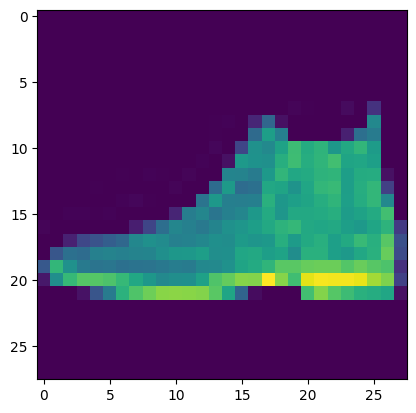

In [14]:
classes = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

model.eval()
x, y = test_data[0][0], test_data[0][1]
with torch.no_grad():
    x = x.to(device)
    pred = model(x)
    predicted, actual = classes[pred[0].argmax(0)], classes[y]
    print(f'Predicted: "{predicted}", Actual: "{actual}"')
print("Входное изображение:")
plt.imshow(np.transpose(x.detach().cpu().numpy(), (1,2,0)))

<h1>Раздел 2<h1>
<h2>Визуализация работы ИИ<h2/>

**Шаг 1** Установка дополнительного пакета *torchcam* для визуализации зон изображений, на основе которых модель принимает решение.

In [15]:
!pip install torch==1.13.1 torchvision==0.14.1 torchaudio==0.13.1
!pip install torchcam

ERROR: Could not find a version that satisfies the requirement torch==1.13.1 (from versions: 2.5.0, 2.5.1, 2.6.0, 2.7.0, 2.7.1, 2.8.0, 2.9.0, 2.9.1, 2.10.0, 2.11.0, 2.12.0, 2.12.1, 2.13.0, 2.14.0, 2.14.1)
ERROR: No matching distribution found for torch==1.13.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 1.5 MB/s eta 0:00:00


Здесь загружается предобученная ResNet18, которая распознаёт изображение и строит карту активации с помощью SmoothGradCAMpp.
Картинка cat.jpg изменяется до 224×224 пикселей — стандартного размера для этой модели. Деление на 255 переводит значения пикселей из диапазона 0–255 в диапазон 0–1. У каждого пикселя цвет задаётся числами от 0 до 255: 0 — отсутствие яркости канала, 255 — максимальная яркость. Делим на 255, чтобы перевести значения в диапазон от 0 до 1. Например, 128 / 255 ≈ 0.502. Так нейросети удобнее обрабатывать входные данные.


 Затем normalize() нормализует RGB-каналы по средним значениям [0.485, 0.456, 0.406] и стандартным отклонениям [0.229, 0.224, 0.225], чтобы подготовить изображение так же, как при обучении ResNet18 на ImageNet.
unsqueeze(0) добавляет размерность батча — модель получает одно изображение в формате [1, 3, 224, 224]. model(input_tensor) выдаёт оценки для 1000 классов, а argmax() выбирает класс с наибольшей оценкой. cam_extractor строит карту активации для этого класса, показывая, на какие области картинки реагирует модель. Последняя строка преобразует карту в формат, подходящий для отображения.

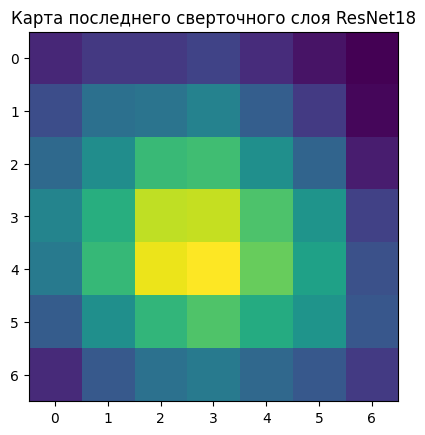

In [17]:
from torchvision.io import read_image
from torchvision.transforms.functional import normalize, resize, to_pil_image
from torchvision.models import resnet18
from torchcam.methods import SmoothGradCAMpp
from torchvision import transforms

model = resnet18(pretrained=True).eval()
cam_extractor = SmoothGradCAMpp(model)
# Открываем картинку
img = read_image("cat.jpg")
# Предобрабатываем картинку для входа нашей нейронной сети
input_tensor = normalize(resize(img, (224, 224)) / 255., [0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

# Получаем выходные данные на основе модели
out = model(input_tensor.unsqueeze(0))
# Получаем карту активации нейроннов последнего слоя модели resnet18
activation_map = cam_extractor(out.squeeze(0).argmax().item(), out)
plt.title("Карта последнего сверточного слоя ResNet18")
plt.imshow(np.transpose(activation_map[0].detach().cpu().numpy(), (1, 2, 0)))

**Шаг 3** Наложение маски на исходное изображение

Открываем изображение с помощью cv2

Сама ResNet18 просто выдаёт предсказание, но не показывает, где именно на изображении находятся важные признаки. Поэтому мы строим тепловую карту: растягиваем её до размера фотографии, раскрашиваем и накладываем поверх оригинала. В результате получаем картинку, на которой цветом выделены области, сильнее связанные с предсказанием модели.
Итог: мы не обучаем новую сеть, а визуализируем работу уже обученной ResNet18, чтобы лучше понять её решение. Это помогает интерпретировать предсказание, хотя карта не гарантирует, что мы точно знаем, почему модель выбрала этот класс.

In [18]:
import cv2
img = cv2.imread("cat.jpg")

Растяжка карты до размеров исходного изображения

In [19]:
heatmap = cv2.resize(activation_map[0].squeeze(0).numpy(), (img.shape[1], img.shape[0]))

Преобразование карты в RGB, наложение на изображение.

Text(0.5, 1.0, 'cat.jpg')

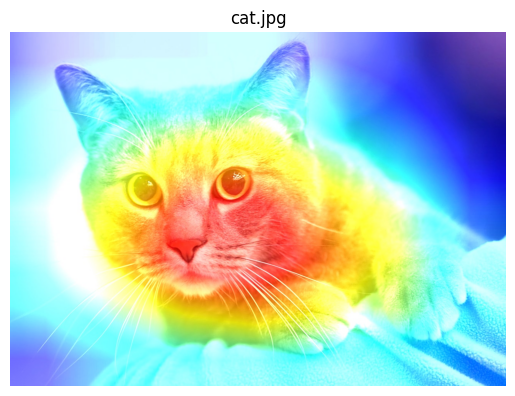

In [20]:
# Загрузить фото кота в локальную среду выполнения ноутбука (сессионное хранилище)
heatmap = np.uint8(255 * heatmap)
heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
hif = .8
superimposed_img = heatmap * hif + img
plt.imshow(superimposed_img)
output = 'output.jpg'
cv2.imwrite(output, superimposed_img)
img=mpimg.imread(output)
plt.imshow(img)
plt.axis('off')
plt.title("cat.jpg")

<h1>Раздел 3</h1>
<h2>Применение state-of-the-art решений на примере датасета FGVAircraft</h2>

**Шаг 1** Аугментация данных.<br/>
Аугментация данных - это умышленное изменение/искажение исходных данных, для улучшения обобщающих способностей при обучении нейронной сети. В качестве аугментации изображений применяют различные повороты, наклоны изображений, изменение цветовых параметров пикселей и т.д.

Здесь мы делаем так, чтобы нейросеть обучалась не на одних и тех же картинках, а на их немного изменённых версиях. Это называется аугментацией данных.
Например, у нас есть фотография кота. Программа может отразить её по горизонтали или вертикали, немного повернуть, изменить яркость и оттенок. При этом кот остаётся котом, просто выглядит немного иначе.
Resize((224, 224)) приводит изображение к нужному размеру, а ToTensor() переводит его в формат, с которым работает PyTorch. Остальные преобразования случайно изменяют картинку: RandomHorizontalFlip() и RandomVerticalFlip() отражают её, RandomRotation(20) поворачивает максимум на 20 градусов в каждую сторону, а ColorJitter() меняет яркость и оттенок.
Зачем всё это? Чтобы нейросеть не просто запоминала конкретные фотографии, а училась распознавать объект, даже если он повёрнут или освещён по-другому. Это помогает ей лучше работать с новыми изображениями.

In [21]:
# описание функции трансформации изображений для реализации аугментаци
augmentation = transforms.Compose([
    # приведение матрицы к тензору pytorch
    ToTensor(),
    # уменьшение размера до 224 на 224 (требование большинства архитектур resnet, vgg ....)
    transforms.Resize((224, 224)),
    # случайное отражение по горизонтали
    transforms.RandomHorizontalFlip(),
    # слаучайное отражение по вертикали
    transforms.RandomVerticalFlip(),
    # случайный поворот изображения до 20 градусов
    transforms.RandomRotation(20),
    # случайное изменение яркости и оттенка изображения
    transforms.ColorJitter(brightness=.3, hue=.2)
])
# подробнее обо всех методах модуля transforms можно узнать в документации https://pytorch.org/vision/stable/transforms.html

Здесь загружается датасет FGVC-Aircraft — набор фотографий самолётов. annotation_level="manufacturer" означает, что нейросеть будет определять производителя самолёта. Для обучения загружается часть train, а для проверки — test. download=True позволяет автоматически скачать датасет, если его ещё нет в папке data.
В обучающей выборке применяется наша аугментация: изображения меняются случайным образом. В тестовой выборке преобразования проще — ToTensor() переводит изображение в тензор, а Resize((224, 224)) приводит его к размеру 224×224 пикселя. Размер одинаковый, чтобы изображения подходили для входа ResNet, а случайные изменения применяются при обучении, но не при проверке.

In [22]:
train = datasets.FGVCAircraft(
      "data",
      annotation_level="manufacturer",
      split="train",
      download=True,
      transform=augmentation
    )

test = datasets.FGVCAircraft(
      "data",
      annotation_level="manufacturer",
      split="test",
      download=True,
      transform=transforms.Compose([ToTensor(), transforms.Resize((224, 224))])
    )

100%|██████████| 2.75G/2.75G [00:35<00:00, 77.5MB/s]


Здесь берём первое изображение из обучающего датасета train[0][0] — оно уже прошло аугментацию, то есть могло повернуться, отразиться или изменить яркость. np.transpose(..., (1, 2, 0)) меняет порядок размерностей с (каналы, высота, ширина) на (высота, ширина, каналы), потому что plt.imshow() ожидает именно такой формат. В итоге мы визуально проверяем, как выглядит изображение после преобразований.

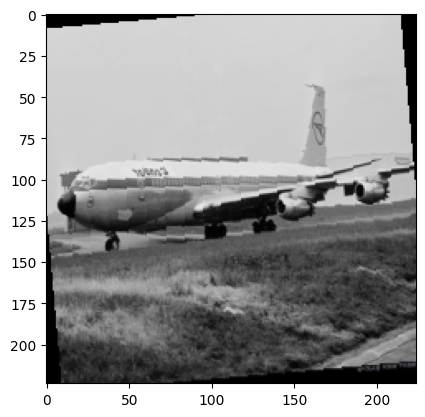

In [23]:
# изображение после аугментации
plt.imshow(np.transpose(train[0][0], (1, 2, 0)))

Здесь создаются загрузчики данных: train_dl подаёт изображения для обучения пакетами по 16 штук, а test_dl — для проверки пакетами по 4 изображения. shuffle=True случайно перемешивает порядок обучающих изображений перед проходом по датасету, чтобы сеть не училась на них всегда в одной последовательности. shuffle=False оставляет тестовые изображения в исходном порядке, потому что при проверке перемешивание не обязательно.

In [24]:
# создание загрузчиков данных, которые будут формировать и подавать данные пакетам на вход модели
train_dl = DataLoader(train, batch_size=16, shuffle=True)
test_dl = DataLoader(test, batch_size=4, shuffle=False)

**Шаг 2** Определение модели. Будем использовать готовую модель архитектуры resnet с 50 слоями.

Здесь создаётся ResNet50 — предобученная нейросеть для распознавания изображений. pretrained=True загружает уже обученные веса модели с ImageNet, поэтому она уже умеет распознавать множество объектов. В выводе видно, что веса размером около 97,8 МБ скачались, а архитектура состоит из свёрточных слоёв, блоков Bottleneck и итогового полносвязного слоя Linear(2048, 1000). Число 1000 означает, что исходная модель распознаёт 1000 классов ImageNet.
Важный момент: дальше модель можно дообучить на нашем датасете самолётов, чтобы она определяла производителя самолёта, а не классы ImageNet. При этом pretrained=True — устаревающий способ записи: в новых версиях torchvision используют weights=ResNet50_Weights.DEFAULT.

In [25]:
from torchvision.models import resnet50

# создание экземпляра модели и инициализация весами, полученными при обучении на датасете ImageNet
model = resnet50(pretrained=True)
model

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 180MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

Так вышло потому, что датасет самолётов и предобученная ResNet50 рассчитаны на разное количество классов.
len(train.classes) возвращает количество классов в нашем датасете — 30 производителей самолётов. А model.fc.out_features показывает количество выходов последнего слоя ResNet50 — 1000 классов ImageNet, на котором модель обучалась изначально.
То есть модель уже умеет распознавать 1000 категорий объектов, но нам нужно, чтобы она различала только 30 категорий производителей самолётов. Поэтому мы заменим последний полносвязный слой model.fc: вместо Linear(2048, 1000) сделаем Linear(2048, 30). Число 2048 — количество признаков, поступающих из предыдущих слоёв, а 30 — количество нужных нам классов.

In [26]:
#  так как в филнальном размер выходного вектора больше необходимого нам количества классов, изменим его!
"Кол-во классов в датасете", len(train.classes), "Кол-во классов предсказываемых моделью:", model.fc.out_features

('Кол-во классов в датасете',
 30,
 'Кол-во классов предсказываемых моделью:',
 1000)

In [27]:
#  изменение размерности выходного вектора и загрузка модели на устройство (cpu или gpu)
model.fc = nn.Linear(model.fc.in_features, len(train.classes))
model = model.to(device)

**Шаг 3** Обучение нейронной сети. Функция для обучения и теста написаны по аналогии с такими же в разделе 1.

Эта функция отвечает за обучение модели на одной эпохе. Она перебирает изображения самолётов, передаёт их модели и сравнивает предсказания с правильными ответами. loss показывает ошибку модели, а total_acc накапливает точность распознавания. Затем loss.backward() рассчитывает градиенты, а optimizer.step() обновляет веса модели, чтобы она училась распознавать самолёты лучше. Каждые 100 батчей выводятся текущие ошибка и точность. В конце функция возвращает среднюю ошибку и точность за всю эпоху.

In [28]:
def train_fn(model, loader, criterion, optimizer):
    total_loss, total_acc = 0, 0

    model.train()

    for batch, (x, y) in enumerate(loader):
      optimizer.zero_grad()
      x,y = x.to(device), y.to(device)
      out = model(x)

      loss = criterion(out, y)

      # рассчет точности
      total_acc += (out.argmax(-1) == y).sum() / out.size(0)
      total_loss += loss.item()

      loss.backward()
      optimizer.step()

      if (batch + 1) % 100 == 0:
        print("-" * 90)
        print("loss:", total_loss / (batch + 1), "acc:", total_acc.item() / (batch + 1), "| batch:", batch+1, "/", len(loader), "|")
    return total_loss / len(loader), total_acc / len(loader)

Эта функция проверяет, насколько хорошо обученная модель распознаёт самолёты на тестовых данных. model.eval() переводит модель в режим проверки, а torch.no_grad() отключает расчёт градиентов, чтобы проверка работала быстрее. Далее модель обрабатывает изображения, вычисляет ошибку loss и точность total_acc. Каждые 100 батчей выводятся текущие результаты, а в конце функция возвращает среднюю ошибку и точность на тестовых данных. Главное отличие от предыдущей функции: здесь модель не обучается и её веса не меняются — мы только проверяем качество распознавания.

In [29]:
def evaluate(model, loader, criterion):
    total_acc, total_loss = 0, 0
    model.eval()

    with torch.no_grad():
      for batch, (x,y) in enumerate(loader):
        x,y = x.to(device), y.to(device)
        out = model(x)

        loss = criterion(out, y)

        total_acc += (out.argmax(-1) == y).sum() / out.size(0)
        total_loss += loss.item()

        if (batch + 1) % 100 == 0:
          print("-" * 90)
          print("loss:", total_loss / (batch + 1), "acc:", total_acc.item() / (batch + 1), "| batch:", batch+1, "/", len(loader), "|")
    return total_loss / len(loader), total_acc / len(loader)

Здесь задаются параметры обучения и запускается сам процесс. epochs = 5 означает, что модель пять раз проходит по всему обучающему набору. Списки train_accs и train_losses сохраняют точность и ошибку на обучении, а test_accs и test_losses — результаты проверки на тестовых данных. Они понадобятся для построения графиков. nn.CrossEntropyLoss() — функция, которая оценивает, насколько предсказания модели отличаются от правильных ответов. torch.optim.Adam(model.parameters(), lr=1e-4) задаёт оптимизатор Adam, который обновляет веса модели. lr=1e-4 — скорость обучения, равная 0,0001.
Затем цикл запускает обучение на каждой эпохе с помощью train_fn(), сохраняет полученные результаты и вызывает evaluate(), чтобы проверить модель на тестовых данных. При проверке веса модели не изменяются.
По результатам видно, что модель постепенно обучается. На первой эпохе точность на обучающих данных составила примерно 31,2%, а на тестовых — 44,1%. Ошибка на тестовых данных составила около 1,65. На пятой эпохе точность на обучающих данных выросла до 76,2%, а на тестовых — до 75,5%. Тестовая ошибка снизилась до 0,77.
Таким образом, за пять эпох точность модели на тестовых данных увеличилась примерно на 31,4 процентного пункта, а значение функции потерь заметно уменьшилось. Это показывает, что модель научилась лучше распознавать дорожные знаки. При этом обучение можно продолжить, чтобы проверить, удастся ли ещё повысить качество классификации.

In [30]:
epochs = 5

train_accs, train_losses = [], []
test_accs, test_losses = [], []

# перекрестная энтропия для рассчета ошибки мультиклассовой классификации
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

print(f"Process started on device: {device}")

for epoch in range(1, epochs + 1):
    loss, acc = train_fn(model, train_dl, criterion, optimizer)
    train_accs.append(acc.detach().cpu().item())
    train_losses.append(loss)
    print("-" * 90)
    print(f"| epoch: {epoch} | train_acc: {acc} | train_loss: {loss} |")
    eloss, eacc = evaluate(model, test_dl, criterion)
    test_accs.append(eacc.detach().cpu().item())
    test_losses.append(eloss)
    print(f"| epoch: {epoch} | test_acc: {eacc}  | test_loss: {eloss}  |")

Process started on device: cuda
------------------------------------------------------------------------------------------
loss: 2.6210548949241637 acc: 0.24625 | batch: 100 / 209 |
------------------------------------------------------------------------------------------
loss: 2.3394010347127914 acc: 0.3090625 | batch: 200 / 209 |
------------------------------------------------------------------------------------------
| epoch: 1 | train_acc: 0.31210124492645264 | train_loss: 2.321658251388221 |
------------------------------------------------------------------------------------------
loss: 0.965295969247818 acc: 0.5975 | batch: 100 / 834 |
------------------------------------------------------------------------------------------
loss: 0.9334035977721215 acc: 0.59375 | batch: 200 / 834 |
------------------------------------------------------------------------------------------
loss: 1.0028393547733625 acc: 0.5825 | batch: 300 / 834 |
--------------------------------------------------

Здесь создаются функции для оценки качества модели. accuracy() считает долю правильных предсказаний, а build_classification_report() формирует отчёт по каждому из 30 классов: показывает точность, полноту и F1-меру. Эти показатели помогают понять, насколько хорошо модель распознаёт каждого производителя самолётов, а не только в целом.
plot_confusion_matrix() строит матрицу ошибок размером 30 на 30. По вертикали указаны истинные классы, по горизонтали — предсказанные. Числа на диагонали показывают правильные предсказания, а остальные ячейки — случаи, когда модель перепутала одного производителя с другим. normalize=True позволяет представить значения в виде долей вместо количества изображений. Цвета помогают визуально оценить результаты, а подписи показывают названия производителей.

In [31]:
import itertools
from sklearn.metrics import classification_report, confusion_matrix


def accuracy(pred, y):
    """функция для расчета точности"""
    vals = (pred.argmax(-1) == y)
    return vals.sum() / pred.size(0)


def build_classification_report(pred, y):
    """функция для построения отчета о классификации, выводит для каждого класса
    полноту, точность, Ф1 меру, поддержку, и макро и средне взвешенные метрики
    для всех классов"""
    return classification_report(y, pred, target_names=train.classes)


def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Матрица ошибок',
                          cmap=plt.cm.Blues):
    """функция для отображения матрицы ошибок классификации"""
    plt.figure(figsize=(20,20), dpi=80)
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=90)
    plt.yticks(tick_marks, classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('Истинные метки')
    plt.xlabel('Предсказанные метки')

Этот код запускает обученную модель на тестовой выборке, чтобы получить предсказания для дальнейшей оценки качества. model.eval() переводит модель в режим проверки, а torch.no_grad() отключает расчёт градиентов, поскольку дообучение здесь не выполняется. В цикле каждое изображение передаётся модели, argmax(-1) выбирает класс с наибольшей оценкой, а preds сохраняет предсказанные классы и ys — правильные ответы. Затем эти данные используются для построения отчёта классификации и матрицы ошибок.
На рисунке показана матрица ошибок для 30 производителей самолётов. По вертикали расположены истинные классы, по горизонтали — предсказанные. Числа на главной диагонали показывают количество правильно классифицированных изображений. Например, для Boeing модель правильно распознала 607 изображений, для Airbus — 309, для Embraer — 192, а для McDonnell Douglas — 137. Значения вне главной диагонали показывают ошибки классификации. Например, 108 изображений Airbus модель ошибочно отнесла к Boeing, а 61 изображение Boeing — к Airbus. Это указывает на то, что некоторые производители имеют визуально похожие самолёты, из-за чего модели бывает сложно их различать. Чем больше значений сосредоточено на главной диагонали и меньше вне её, тем лучше модель распознаёт классы.

In [32]:
#  прогон модели на тестовой выборке для получения меток для дальнейшего расчета метрик
preds = []
ys = []
model.eval()
with torch.no_grad():
  for batch, (x, y) in enumerate(test_dl):
    predicted = model(x.to(device))
    preds.extend(predicted.argmax(-1).detach().cpu().tolist())
    ys.extend(y.tolist())

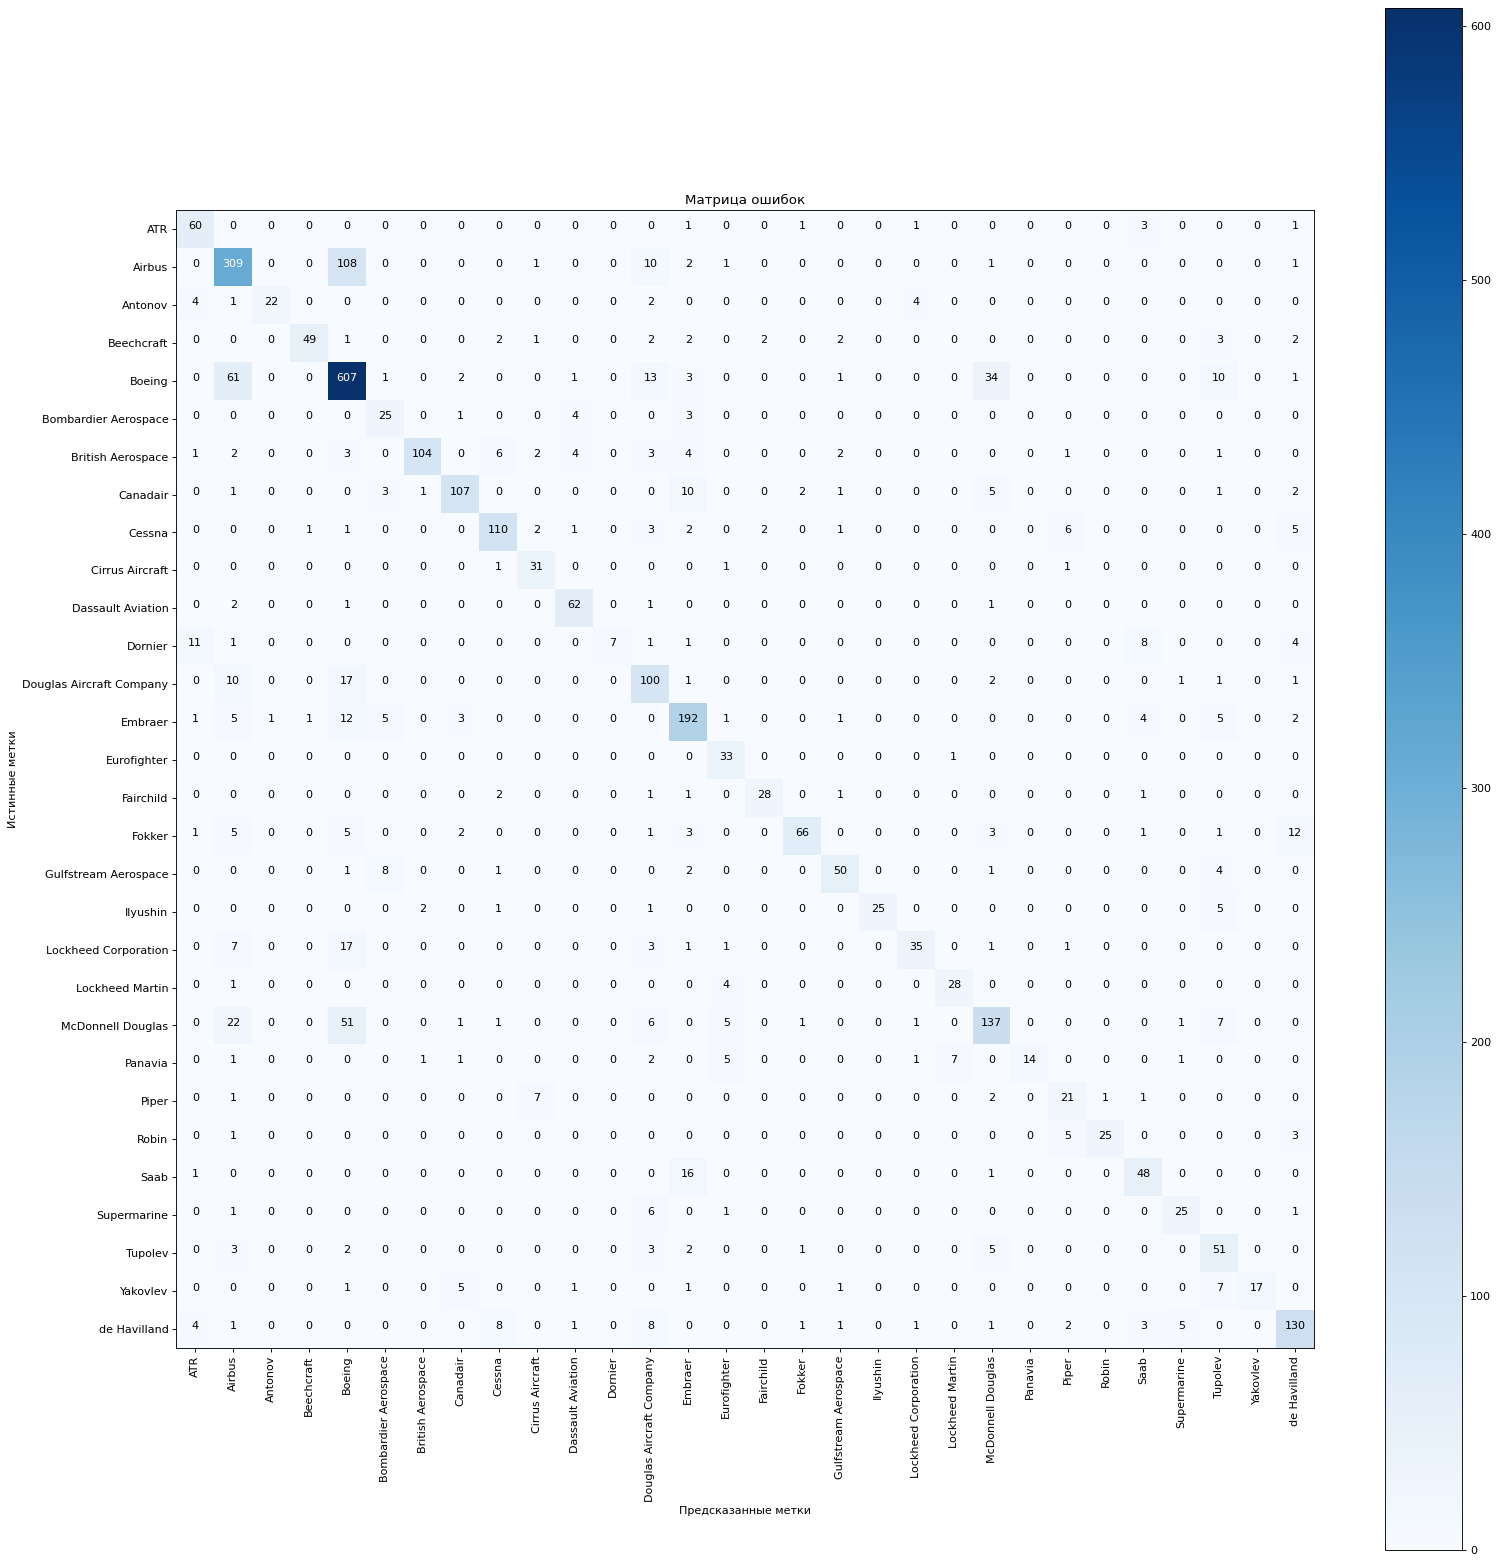

In [33]:
plot_confusion_matrix(confusion_matrix(ys, preds), train.classes)

Здесь вызывается build_classification_report(preds, ys), которая формирует подробный отчёт о качестве распознавания каждого производителя самолётов. Поскольку классов много и вывод получается длинным, отчёт можно сохранять в файл для удобного просмотра.
В отчёте представлены четыре основных показателя: precision показывает, насколько точны предсказания класса, recall — какую долю реальных объектов этого класса модель правильно распознала, f1-score — баланс между точностью и полнотой, а support — количество изображений данного класса в тестовой выборке.
По новым результатам, для Boeing полнота (recall) составляет 0,83: модель правильно распознала около 83% из 734 изображений этого производителя. Для Dornier полнота составляет 0,21, то есть правильно классифицировано примерно 21% из 33 изображений. При этом precision для Dornier равен 1,00: все изображения, которые модель отнесла к этому классу, были классифицированы правильно, но сама модель распознала далеко не все реальные изображения Dornier. Хорошие результаты также наблюдаются у Dassault Aviation: recall равен 0,93, а f1-score — 0,88. Такой отчёт позволяет определить, какие производители распознаются хорошо, а какие модель часто пропускает или путает с другими классами.

In [34]:
# не имеет смысла в данном случае, так как слишком много классов
# самостоятельно измените функцию build_classification_report для вывода отчета в файл!
build_classification_report(preds, ys)

'                          precision    recall  f1-score   support\n\n                     ATR       0.72      0.90      0.80        67\n                  Airbus       0.71      0.71      0.71       433\n                 Antonov       0.96      0.67      0.79        33\n              Beechcraft       0.96      0.74      0.84        66\n                  Boeing       0.73      0.83      0.78       734\n    Bombardier Aerospace       0.60      0.76      0.67        33\n       British Aerospace       0.96      0.78      0.86       133\n                Canadair       0.88      0.80      0.84       133\n                  Cessna       0.83      0.82      0.83       134\n         Cirrus Aircraft       0.70      0.91      0.79        34\n       Dassault Aviation       0.84      0.93      0.88        67\n                 Dornier       1.00      0.21      0.35        33\nDouglas Aircraft Company       0.60      0.75      0.67       133\n                 Embraer       0.78      0.82      0.80    

Здесь строятся два графика изменения ошибки и точности модели за пять эпох. На первом графике показаны результаты обучения: train_losses — ошибка, train_accs — точность. На втором — результаты проверки на тестовых данных: test_losses и test_accs. По оси X указаны эпохи от 0 до 4, а по оси Y — значения ошибки и точности.
По новым графикам видно, что модель постепенно улучшает качество распознавания производителей самолётов. На обучении ошибка снизилась примерно с 2,32 до 0,76, а точность выросла с 31,2% до 76,2%. На тестовых данных ошибка уменьшилась примерно с 1,65 до 0,77, а точность увеличилась с 44,1% до 75,5%. Это свидетельствует о том, что в ходе обучения модель научилась лучше классифицировать изображения. К концу пятой эпохи показатели на обучающей и тестовой выборках стали близкими, что указывает на согласованное улучшение результатов. plt.legend() добавляет легенду, поясняющую линии графика, а plt.show() выводит графики на экран.

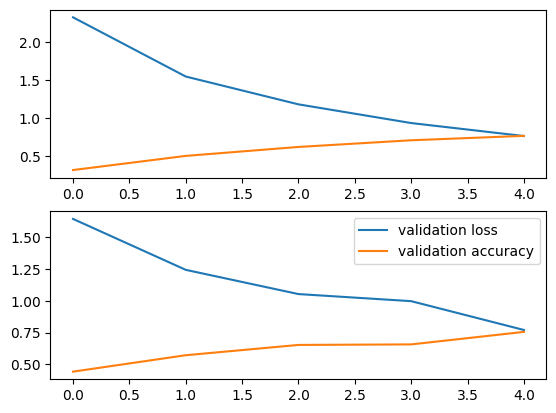

In [35]:
# график изменения ошибки и точности от эпохи
fig = plt.figure(num = 2)
fig1 = fig.add_subplot(2,1,1)
fig2 = fig.add_subplot(2,1,2)
fig1.plot(train_losses, label = 'training loss')
fig1.plot(train_accs, label = 'training accuracy')
fig2.plot(test_losses, label = 'validation loss')
fig2.plot(test_accs, label = 'validation accuracy')
plt.legend()
plt.show()

**Задание** создайте тепловую карту последнего сверточного слоя модели resnet50, посмотрите и проанализируйте, корректно ли модель делает акцент для принятия решения или использует косвенные признаки (читерит)!

В этом задании я использую Grad-CAM, чтобы понять, на какие части изображения обращает внимание модель ResNet50 при распознавании самолётов. Сначала я беру изображение из тестовой выборки и передаю его в модель. Она определяет наиболее вероятный класс самолёта. Затем я сравниваю предсказанный класс с истинной меткой, чтобы проверить, правильно ли модель классифицировала изображение.
Затем я выбираю последний свёрточный слой ResNet50, потому что он содержит признаки, которые модель выделяет при обработке изображения. Grad-CAM использует активации этого слоя и градиенты для построения тепловой карты, которая показывает, какие области изображения связаны с предсказанием модели.
После этого я накладываю тепловую карту на исходное изображение. Красные и жёлтые области соответствуют более высокой значимости для предсказания, а синие — более низкой. Благодаря этому можно визуально оценить, какие части изображения вносят наибольший вклад в решение нейросети.
На представленном рисунке истинный класс самолёта — Boeing, и модель также предсказала Boeing. Следовательно, на этом примере классификация выполнена правильно. На тепловой карте наиболее выраженная активация наблюдается в центральной части изображения, преимущественно в области фюзеляжа и рядом с крылом. При этом область высокой активации занимает не весь самолёт равномерно, а сосредоточена преимущественно в его центральной части. Это позволяет предположить, что соответствующие визуальные признаки повлияли на предсказание модели. Вместе с тем тепловая карта частично захватывает окружающие области, поэтому нельзя утверждать, что модель учитывала исключительно сам самолёт, а не фон. Таким образом, на данном примере Grad-CAM позволяет визуально исследовать решение модели и показать области изображения, связанные с правильной классификацией. Однако для оценки поведения модели в целом необходимо проверить дополнительные изображения, в том числе примеры, в которых класс был предсказан неверно.
Свёрточная нейронная сеть, или CNN, — это нейросеть, которая умеет находить признаки на изображениях. Например, сначала она распознаёт простые элементы: линии, границы и текстуры. Затем объединяет их в более сложные признаки: детали крыльев, фюзеляж и форму самолёта. На основе этих признаков модель определяет класс изображения.
В начале я использую ResNet50, предварительно обученную на большом наборе изображений ImageNet. Затем заменяю её последний классификационный слой, потому что мне нужно распознавать 30 классов производителей самолётов. Во время обучения модель получает изображения и правильные метки классов. Она делает предсказание, сравнивает его с правильным ответом с помощью функции потерь и вычисляет ошибку. Затем с помощью обратного распространения ошибки и оптимизатора Adam корректируются обучаемые веса модели, чтобы уменьшить эту ошибку. Этот процесс повторяется на множестве изображений в течение нескольких эпох.
Adam — это оптимизатор, который обновляет веса нейросети на основе вычисленных градиентов. Его задача — помочь модели постепенно уменьшать ошибку во время обучения.

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 4.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=c723d834645a5b81e09ffba1676392106641127c1ac53944eef795be2bc47f7b
  Stored in directory: /root/.cache/pip/wheels/91/36/f0/c2367865493d51b13369769181beca14603d17d6539a5922e3
Successfully built grad-cam


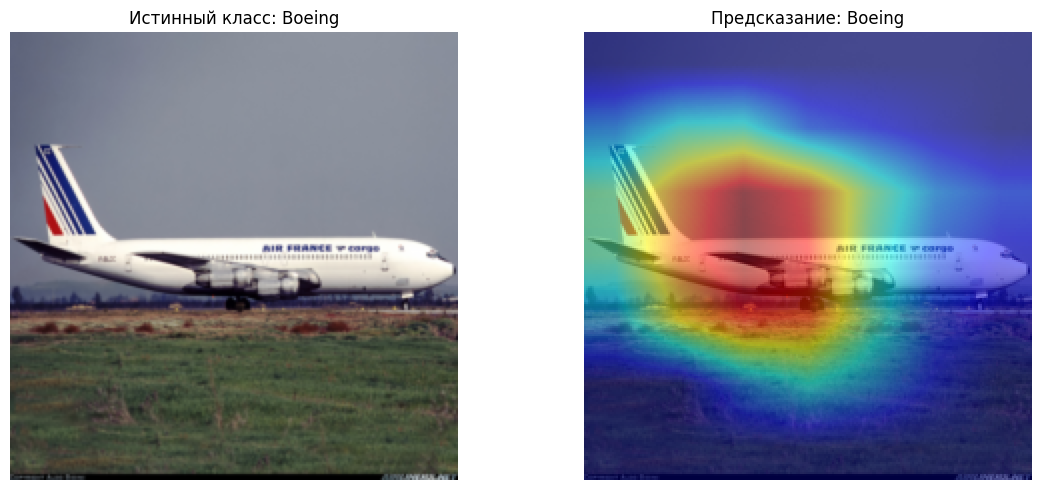

In [36]:
# Если библиотека ещё не установлена:
!pip install grad-cam

import numpy as np
import matplotlib.pyplot as plt
import torch
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image


model = model.to(device)
model.eval()
# Берём одно изображение из тестовой выборки
x, y = next(iter(test_dl))
input_tensor = x[0:1].to(device)

# Получаем предсказанный класс
with torch.no_grad():
    output = model(input_tensor)
    pred_class = output.argmax(dim=1).item()

# Последний свёрточный слой ResNet50
target_layers = [model.layer4[-1].conv3]

# Строим тепловую карту
with GradCAM(
    model=model,
    target_layers=target_layers
) as cam:
    targets = [ClassifierOutputTarget(pred_class)]
    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=targets
    )[0]

# Исходное изображение для наложения карты
rgb_img = x[0].permute(1, 2, 0).cpu().numpy()
rgb_img = np.clip(rgb_img, 0, 1)

visualization = show_cam_on_image(
    rgb_img,
    grayscale_cam,
    use_rgb=True
)

# Выводим изображение и тепловую карту
true_class = train.classes[y[0].item()]
predicted_class = train.classes[pred_class]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb_img)
plt.title(f"Истинный класс: {true_class}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(visualization)
plt.title(f"Предсказание: {predicted_class}")
plt.axis("off")

plt.tight_layout()
plt.show()

<H1>Раздел 4</H1>
<h2>Классификация дорожных знаков</h2>

Изначально в коде была функция augmentation_fn_builder(img_size), которая задавала преобразования изображений. Resize менял размер картинки на 224 × 224 пикселя, а ToTensor преобразовывал её в числовой формат, с которым работает нейросеть. Но в задании просили дополнить функцию аугментацией.
Поэтому я добавил три преобразования. Первое — RandomRotation(10): оно слегка поворачивает изображение, чтобы модель умела распознавать немного наклонённые знаки. Второе — RandomAffine со сдвигом: оно меняет положение знака в кадре. Третье — ColorJitter: оно меняет яркость и контраст, имитируя разные условия освещения.
Это нужно, чтобы модель не запоминала только конкретные изображения, а училась распознавать дорожные знаки при небольших изменениях положения и освещения.
Для обучающей выборки train я применил все эти преобразования, а для тестовой test оставил только изменение размера и перевод в тензор. Так тестовые изображения не меняются случайным образом, и можно объективнее оценить качество модели.

In [37]:
def augmentation_fn_builder(img_size):
    augmentation = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.RandomRotation(10),  # Случайный поворот до ±10 градусов
        transforms.RandomAffine(
            degrees=0,
            translate=(0.1, 0.1)  # Случайный сдвиг изображения
        ),
        transforms.ColorJitter(
            brightness=0.2,
            contrast=0.2  # Случайное изменение яркости и контраста
        ),
        transforms.ToTensor()  # Преобразование изображения в тензор
    ])
    return augmentation


train = datasets.GTSRB(
    "data",
    split="train",
    download=True,
    transform=augmentation_fn_builder(224)
)

test = datasets.GTSRB(
    "data",
    split="test",
    download=True,
    transform=transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor()
    ])
)

100%|██████████| 187M/187M [00:03<00:00, 51.9MB/s]
100%|██████████| 89.0M/89.0M [00:02<00:00, 35.4MB/s]
100%|██████████| 99.6k/99.6k [00:00<00:00, 1.39MB/s]


Здесь я проверяю, сколько разных классов дорожных знаков есть в обучающей выборке. Я перебираю изображения, проверяю их метки и добавляю каждый класс в список только один раз. В конце считаю количество уникальных классов. Это позволяет убедиться, сколько категорий знаков представлено в датасете

In [38]:
unique = []
for x, y in train:
  if y not in unique:
    unique.append(y)
len(unique)

43

Здесь мы создаём DataLoader — инструмент, который передаёт изображения из датасета нейросети небольшими группами, то есть батчами.
В первой строке DataLoader(train, batch_size=16, shuffle=True) создаётся загрузчик обучающей выборки. batch_size=16 означает, что модель получает по 16 изображений за один батч, а shuffle=True перемешивает изображения перед каждой эпохой обучения. Это помогает модели не обучаться всегда в одном и том же порядке.
Во второй строке DataLoader(test, batch_size=14, shuffle=False) создаётся загрузчик тестовой выборки. Здесь модель получает по 14 изображений за один батч, а shuffle=False означает, что порядок изображений сохраняется. Так удобнее сопоставлять предсказания с исходными метками.

In [39]:
train_dl = DataLoader(train, batch_size=16, shuffle=True)
test_dl = DataLoader(test, batch_size=14, shuffle=False)

Первая строка resnet50(pretrained=True) загружает ResNet50 с предварительно обученными весами. Это значит, что модель уже научилась выделять признаки изображений на большом наборе данных ImageNet, и нам не нужно начинать обучение с нуля.
Во второй строке nn.Linear(2048, len(unique)) мы заменяем последний классификационный слой. Изначально ResNet50 рассчитана на 1000 классов ImageNet, а нам нужно распознавать дорожные знаки. Поэтому на вход нового слоя подаются 2048 признаков, а количество выходов равно числу уникальных классов в нашем датасете.
Последняя строка model.to(device) переносит модель на GPU, если он доступен, или на CPU. Это нужно, чтобы модель работала на том же устройстве, что и входные изображения.

In [40]:
model = resnet50(pretrained=True)
model.fc = nn.Linear(2048, len(unique))
model = model.to(device)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


В этом коде реализованы две функции. Первая отвечает за обучение ResNet50: модель получает изображения дорожных знаков, выдаёт предсказания, после чего вычисляется функция потерь. Затем с помощью обратного распространения ошибки рассчитываются градиенты, а оптимизатор обновляет веса модели. Параллельно накапливаются значения ошибки и точности.
Вторая функция оценивает качество обученной модели на проверочных данных. Она переключает модель в режим оценки и отключает вычисление градиентов, поскольку обновлять веса не нужно. Обе функции возвращают средние значения ошибки и точности, чтобы можно было сравнивать результаты обучения и проверки».
Важный нюанс: сейчас точность усредняется по пакетам, а не по отдельным изображениям. Поскольку последний пакет может быть меньше остальных, итоговая точность может быть немного неточной. Для учебного эксперимента это часто допустимо, но для более точного расчёта лучше суммировать количество верных предсказаний и делить на общее число изображений

In [41]:
def train_fn(model, loader, criterion, optimizer):
    total_loss, total_acc = 0, 0

    model.train()

    for batch, (x, y) in enumerate(loader):
      optimizer.zero_grad()
      x,y = x.to(device), y.to(device)
      out = model(x)

      loss = criterion(out, y)

      # рассчет точности
      total_acc += (out.argmax(-1) == y).sum() / out.size(0)
      total_loss += loss.item()

      loss.backward()
      optimizer.step()

      if (batch + 1) % 100 == 0:
        print("-" * 90)
        print("loss:", total_loss / (batch + 1), "acc:", total_acc.item() / (batch + 1), "| batch:", batch+1, "/", len(loader), "|")
    return total_loss / len(loader), total_acc / len(loader)


def evaluate(model, loader, criterion):
    total_acc, total_loss = 0, 0
    model.eval()

    with torch.no_grad():
      for batch, (x,y) in enumerate(loader):
        x,y = x.to(device), y.to(device)
        out = model(x)

        loss = criterion(out, y)

        total_acc += (out.argmax(-1) == y).sum() / out.size(0)
        total_loss += loss.item()

        if (batch + 1) % 100 == 0:
          print("-" * 90)
          print("loss:", total_loss / (batch + 1), "acc:", total_acc.item() / (batch + 1), "| batch:", batch+1, "/", len(loader), "|")
    return total_loss / len(loader), total_acc / len(loader)

В этом блоке задаётся процесс обучения модели. Я устанавливаю одну эпоху, создаю списки для сохранения значений ошибки и точности, выбираю функцию потерь CrossEntropyLoss и оптимизатор Adam со скоростью обучения 0,0001. Далее запускается цикл обучения: функция train_fn обучает модель на обучающих данных и возвращает метрики. После этого функция evaluate проверяет качество модели на тестовых данных без изменения весов. Полученные значения сохраняются в списках, чтобы затем можно было анализировать результаты и строить графики.
В данном эксперименте обучение выполняется на GPU (cuda) в течение одной эпохи. По результатам видно, что модель показала высокое качество уже после первого прохода по обучающей выборке. Точность на обучающих данных составила 94,58%, а значение функции потерь — 0,235. На тестовой выборке точность достигла 97,94%, а ошибка составила примерно 0,083. Это показывает, что модель успешно классифицирует изображения производителей самолётов на тестовых данных.
При этом тестовая точность оказалась выше обучающей. Такое возможно из-за различий между обучающей и тестовой выборками, а также из-за применения аугментаций во время обучения. Однако для окончательного вывода о качестве модели желательно дополнительно проверить распределение классов и убедиться, что обучающие и тестовые изображения не имеют нежелательного пересечения.

In [42]:
epochs = 1

train_accs, train_losses = [], []
test_accs, test_losses = [], []

# перекрестная энтропия для рассчета ошибки мультиклассовой классификации
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

print(f"Process started on device: {device}")

for epoch in range(1, epochs + 1):
    loss, acc = train_fn(model, train_dl, criterion, optimizer)
    train_accs.append(acc.detach().cpu().item())
    train_losses.append(loss)
    print("-" * 90)
    print(f"| epoch: {epoch} | train_acc: {acc} | train_loss: {loss} |")
    eloss, eacc = evaluate(model, test_dl, criterion)
    test_accs.append(eacc.detach().cpu().item())
    test_losses.append(eloss)
    print(f"| epoch: {epoch} | test_acc: {eacc}  | test_loss: {eloss}  |")

Process started on device: cuda
------------------------------------------------------------------------------------------
loss: 1.9612789177894592 acc: 0.520625 | batch: 100 / 1665 |
------------------------------------------------------------------------------------------
loss: 1.3030032389611006 acc: 0.6865625 | batch: 200 / 1665 |
------------------------------------------------------------------------------------------
loss: 0.9546170413245757 acc: 0.774375 | batch: 300 / 1665 |
------------------------------------------------------------------------------------------
loss: 0.7581434060400352 acc: 0.82171875 | batch: 400 / 1665 |
------------------------------------------------------------------------------------------
loss: 0.6314055856466293 acc: 0.851875 | batch: 500 / 1665 |
------------------------------------------------------------------------------------------
loss: 0.5410795569225836 acc: 0.8732291666666666 | batch: 600 / 1665 |
-------------------------------------------

Эта команда визуализирует первое изображение из тестового набора данных. Сначала я получаю изображение из датасета, затем с помощью np.transpose меняю порядок размерностей с формата PyTorch (каналы, высота, ширина) на формат Matplotlib (высота, ширина, каналы). После этого plt.imshow() отображает дорожный знак на экране»

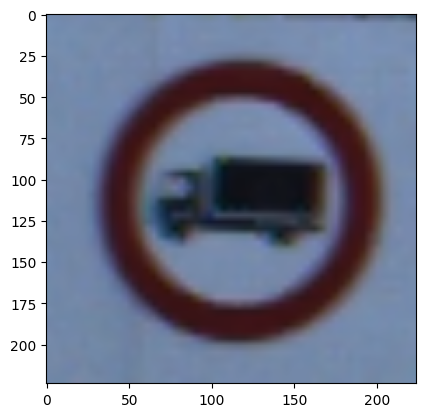

In [43]:
plt.imshow(np.transpose(test[0][0], (1, 2, 0)))

Создаем тепловую карту последнего сверточного слоя сети

В первой команде я преобразую первое изображение тестового набора из тензора PyTorch в формат PIL и сохраняю его в файл sign.png. Во второй команде сохраняю обученные параметры ResNet50 в файл resnet50.pt. Перед сохранением модель переносится на CPU, а метод state_dict() извлекает её веса и смещения. Это позволяет в дальнейшем восстановить обученную модель без повторного обучения, если заново создать архитектуру и загрузить сохранённые параметры

In [44]:
to_pil_image(test[0][0]).save("sign.png")
torch.save(model.cpu().state_dict(), "resnet50.pt")

В этом блоке я восстанавливаю архитектуру ResNet50 с выходным слоем для нужного количества классов и загружаю ранее сохранённые обученные веса. Затем считываю изображение дорожного знака и выполняю предобработку: изменяю размер до 224 × 224 пикселей, масштабирую значения пикселей и нормализую RGB-каналы. Модель вычисляет оценки для всех классов, после чего выбирается класс с максимальной оценкой. С помощью SmoothGradCAM++ строится карта активации, позволяющая визуально оценить, какие области карты признаков связаны с предсказанием нейросети.
На рисунке представлена карта активации последнего свёрточного слоя ResNet50. Наиболее выраженная активация обозначена жёлтым цветом и расположена ближе к центральной части карты, тогда как фиолетовые и синие области характеризуются меньшей интенсивностью. Это показывает, что вклад различных пространственных областей в активацию признаков неодинаков. Однако сама карта не позволяет определить, какому конкретному элементу дорожного знака соответствует яркая область. Для более наглядной интерпретации необходимо совместить карту активации с исходным изображением.

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


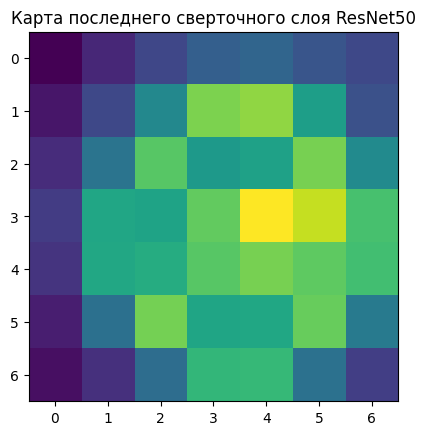

In [45]:
model = resnet50(pretrained=False)
model.fc = nn.Linear(2048, len(unique))
model = model.eval()
model.load_state_dict(torch.load("resnet50.pt"))
cam_extractor = SmoothGradCAMpp(model)
# Открываем картинку
img = read_image("sign.png")
# Предобрабатываем картинку для входа нашей нейронной сети
input_tensor = normalize(resize(img, (224, 224)) / 255., [0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

# Получаем выходные данные на основе модели
out = model(input_tensor.unsqueeze(0))
# Получаем карту активации нейроннов последнего слоя модели resnet18
activation_map = cam_extractor(out.squeeze(0).argmax().item(), out)
plt.title("Карта последнего сверточного слоя ResNet50")
plt.imshow(np.transpose(activation_map[0].detach().cpu().numpy(), (1, 2, 0)))

На этом этапе я совмещаю тепловую карту SmoothGradCAM++ с исходным изображением дорожного знака. Сначала загружаю изображение и изменяю размер карты активации под его размеры. Затем преобразую значения карты в диапазон, подходящий для цветовой визуализации, и применяю цветовую схему JET. После этого накладываю карту на оригинал, сохраняю результат в файл output.jpg и отображаю его без координатных осей. Полученное изображение позволяет визуально оценить, какие области дорожного знака связаны с предсказанием модели.
На полученном изображении наиболее выраженные области активации выделены красным цветом и расположены преимущественно в центральной части знака, а также в области красной горизонтальной полосы. Жёлтые и оранжевые области охватывают значительную часть круглой границы знака, тогда как синие и голубые области по краям имеют меньшую интенсивность. Это позволяет предположить, что центральная часть знака и его характерная форма вносят вклад в предсказание нейросети. Однако тепловая карта показывает значимость областей для модели, а не доказывает, что она распознаёт знак исключительно по этим деталям.
При отображении также появляется предупреждение Clipping input data, поскольку значения изображения после наложения тепловой карты выходят за допустимый диапазон для plt.imshow(). Поэтому цвета на итоговой визуализации могут отображаться некорректно. Это предупреждение не обязательно означает ошибку классификации, но для корректного отображения изображения следует привести значения пикселей к диапазону от 0 до 255 или от 0 до 1 в зависимости от используемого формата.

Text(0.5, 1.0, 'sign.png')

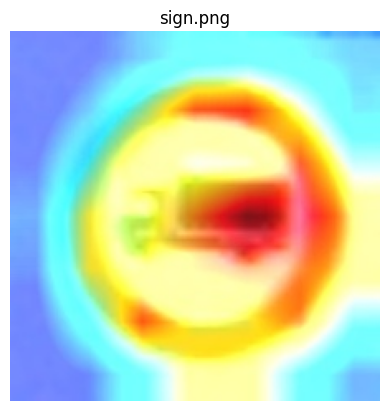

In [46]:
# действия аналогичны разделу 2
img = cv2.imread("sign.png")
heatmap = cv2.resize(activation_map[0].squeeze(0).numpy(), (img.shape[1], img.shape[0]))
heatmap = np.uint8(255 * heatmap)
heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
hif = .8
superimposed_img = heatmap * hif + img
plt.imshow(superimposed_img)
output = 'output.jpg'
cv2.imwrite(output, superimposed_img)
img=mpimg.imread(output)
plt.imshow(img)
plt.axis('off')
plt.title("sign.png")

In [51]:
%cd /content
!git ls-remote https://github.com/LycosidaeDan/prz-1_Orlov_ASZII.git

/content


In [52]:
!git clone https://github.com/LycosidaeDan/prz-1_Orlov_ASZII.git

fatal: destination path 'prz-1_Orlov_ASZII' already exists and is not an empty directory.


In [53]:
%cd /content/prz-1_Orlov_ASZII
!ls -la
!git status
!git remote -v

/content/prz-1_Orlov_ASZII
total 12
drwxr-xr-x 3 root root 4096 Oct 14 11:27 .
drwxr-xr-x 1 root root 4096 Oct 14 11:27 ..
drwxr-xr-x 7 root root 4096 Oct 14 11:27 .git
On branch main

No commits yet

nothing to commit (create/copy files and use "git add" to track)
origin	https://github.com/LycosidaeDan/prz-1_Orlov_ASZII.git (fetch)
origin	https://github.com/LycosidaeDan/prz-1_Orlov_ASZII.git (push)


In [54]:
%cd /content

!cp -n output.jpg sign.png cat.jpg resnet50.pt /content/prz-1_Orlov_ASZII/

%cd /content/prz-1_Orlov_ASZII
!git status

/content
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
/content/prz-1_Orlov_ASZII
On branch main

No commits yet

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	cat.jpg
	output.jpg
	resnet50.pt
	sign.png

nothing added to commit but untracked files present (use "git add" to track)


In [56]:
!git config user.name "LycosidaeDan"
!git config user.email "orlovdanila749@gmail.com"

In [57]:
%cd /content/prz-1_Orlov_ASZII

!git add cat.jpg output.jpg sign.png resnet50.pt
!git commit -m "Orlov_Danila_Sergeevich_prz_1"
!git push -u origin main

/content/prz-1_Orlov_ASZII
[main (root-commit) bd640af] Orlov_Danila_Sergeevich_prz_1
 4 files changed, 0 insertions(+), 0 deletions(-)
 create mode 100644 cat.jpg
 create mode 100644 output.jpg
 create mode 100644 resnet50.pt
 create mode 100644 sign.png
fatal: could not read Username for 'https://github.com': No such device or address


In [73]:
!git push origin main

fatal: could not read Username for 'https://github.com': No such device or address


In [71]:
%cd /content/prz-1_Orlov_ASZII
!git add AZSII_prz_1.ipynb
!git commit --amend --no-edit
!git log -1 --oneline

/content/prz-1_Orlov_ASZII
[main 73041d1] Add practical work notebook
 Date: Wed Oct 14 11:43:33 2026 +0000
 1 file changed, 1 insertion(+)
 create mode 100644 AZSII_prz_1.ipynb
73041d1 (HEAD -> main) Add practical work notebook


In [ ]:
[REDACTED_TOKEN]